Building Electricity Consumption Prediction

In [3]:
import pandas as pd

file_path = ("/home/parsian/Documents/"
    "Building Electricity Consumption Prediction/"
    "data/raw/energydata_complete.csv")
data = pd.read_csv(file_path)
data.info()
data["date"] = pd.to_datetime(data["date"])
print(data["date"].diff().head())
print(data["date"].diff().value_counts())
print(data.head())
print(data.shape)
print(data["date"].head())


<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9           19

In [4]:
data["target_next_10min"] = data["Appliances"].shift(-1)
labeled_data = data.dropna(subset= ["target_next_10min"])
print(data[["Appliances", "target_next_10min"]].head())
print(data[["Appliances", "target_next_10min"]].tail())
print(labeled_data[["Appliances", "target_next_10min"]].tail())
print(labeled_data["target_next_10min"].isna().sum())
print(labeled_data.shape)



   Appliances  target_next_10min
0          60               60.0
1          60               50.0
2          50               50.0
3          50               60.0
4          60               50.0
       Appliances  target_next_10min
19730         100               90.0
19731          90              270.0
19732         270              420.0
19733         420              430.0
19734         430                NaN
       Appliances  target_next_10min
19729          90              100.0
19730         100               90.0
19731          90              270.0
19732         270              420.0
19733         420              430.0
0
(19734, 30)


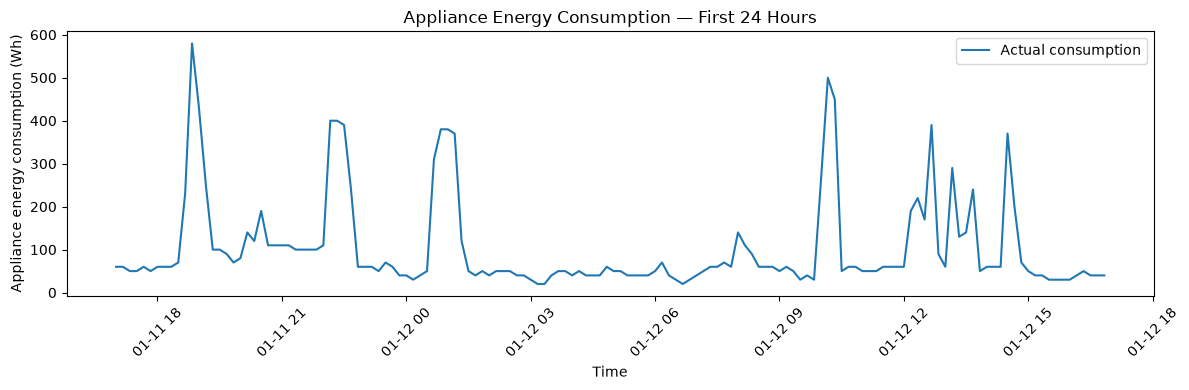

In [5]:
import matplotlib.pyplot as plt

plot_data = labeled_data.head(144)
plt.figure(figsize=(12, 4))
plt.plot(plot_data["date"], plot_data["Appliances"], label="Actual consumption")
plt.xlabel("Time")
plt.ylabel("Appliance energy consumption (Wh)")
plt.title("Appliance Energy Consumption — First 24 Hours")
plt.legend()
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [14]:
n_row = len(labeled_data)
train_end = int(n_row * 0.70)
train_data = labeled_data.iloc[:train_end]
val_size = int(n_row * 0.15)
val_end = train_end + val_size
val_data = labeled_data.iloc[train_end:val_end]
test_data = labeled_data.iloc[val_end:]
print("Total rows:", n_row)
print("Validation starts at index:", train_end)
print("Training rows:", len(train_data))
print("Test starts at index:", val_end)
print("Validation rows:", len(val_data))
print("Test rows:", len(test_data))

Total rows: 19734
Validation starts at index: 13813
Training rows: 13813
Test starts at index: 16773
Validation rows: 2960
Test rows: 2961
